       NETFLIX CONTENT ANALYSIS PROJECT

1. DATASET LOADED SUCCESSFULLY!
Original dataset shape: (8154, 12)

2. FIRST FIVE ROWS


,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,NaN,United States,"September 25, 2021",2020,PG-13,90 min,Documentaries,"As her father nears the end of his life, filmm..."
1,s2,TV Show,Blood & Water,NaN,"Ama Qamata, Khosi Ngema, Gail Mabalane, Thaban...",South Africa,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, TV Dramas, TV Mysteries","After crossing paths at a party, a Cape Town t..."
2,s3,TV Show,Ganglands,Julien Leclercq,"Sami Bouajila, Tracy Gotoas, Samuel Jouy, Nabi...",NaN,"September 24, 2021",2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act...",To protect his family from a powerful drug lor...
3,s4,TV Show,Jailbirds New Orleans,NaN,NaN,NaN,"September 24, 2021",2021,TV-MA,1 Season,"Docuseries, Reality TV","Feuds, flirtations and toilet talk go down amo..."
4,s5,TV Show,Kota Factory,NaN,"Mayur More, Jitendra Kumar, Ranjan Raj, Alam K...",India,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, Romantic TV Shows, TV ...",In a city of coaching centers known to train I...



3. COLUMN NAMES
['show_id', 'type', 'title', 'director', 'cast', 'country', 'date_added', 'release_year', 'rating', 'duration', 'listed_in', 'description']

4. DATASET INFORMATION
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8154 entries, 0 to 8153
Data columns (total 12 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   show_id       8154 non-null   object
 1   type          8154 non-null   object
 2   title         8154 non-null   object
 3   director      5636 non-null   object
 4   cast          7407 non-null   object
 5   country       7351 non-null   object
 6   date_added    8145 non-null   object
 7   release_year  8154 non-null   int64 
 8   rating        8150 non-null   object
 9   duration      8150 non-null   object
 10  listed_in     8153 non-null   object
 11  description   8153 non-null   object
dtypes: int64(1), object(11)
memory usage: 764.6+ KB

5. MISSING VALUES IN EACH COLUMN
show_id            0
type            

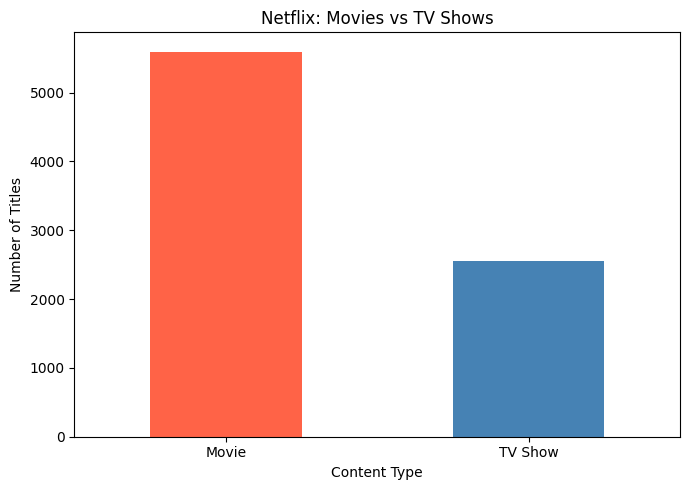


TOP 10 GENRES
listed_in
International Movies        2571
Dramas                      2208
Comedies                    1541
International TV Shows      1306
Documentaries                779
Action & Adventure           777
TV Dramas                    734
Independent Movies           668
Children & Family Movies     594
Romantic Movies              577
Name: count, dtype: int64


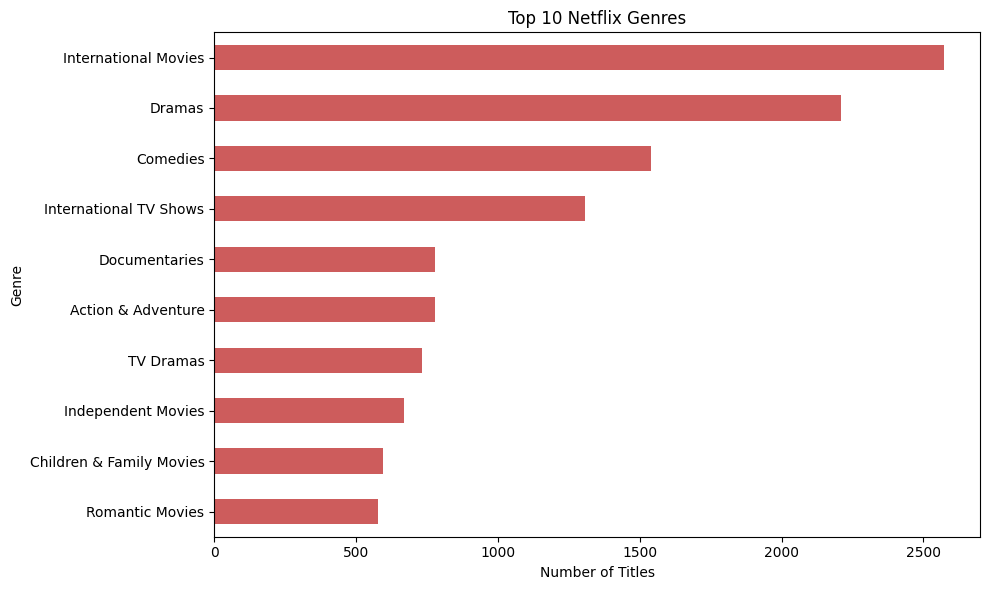


RELEASE YEAR STATISTICS
Oldest release year: 1925
Latest release year in dataset: 2021


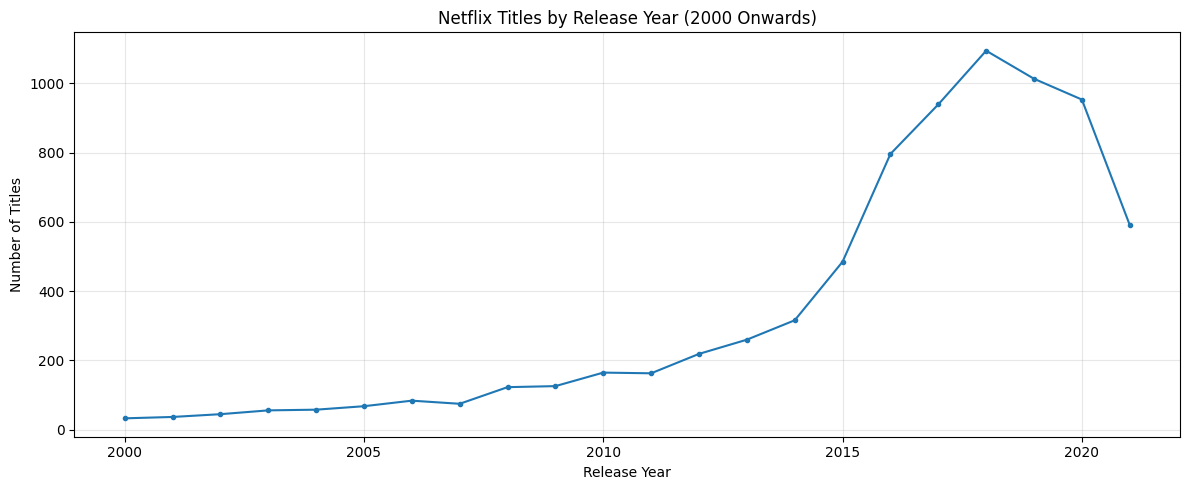


TOP 10 COUNTRIES BY TITLE ASSOCIATIONS
country
United States     3335
India              986
United Kingdom     694
Canada             397
France             366
Japan              310
Spain              222
South Korea        219
Germany            205
Mexico             160
Name: count, dtype: int64


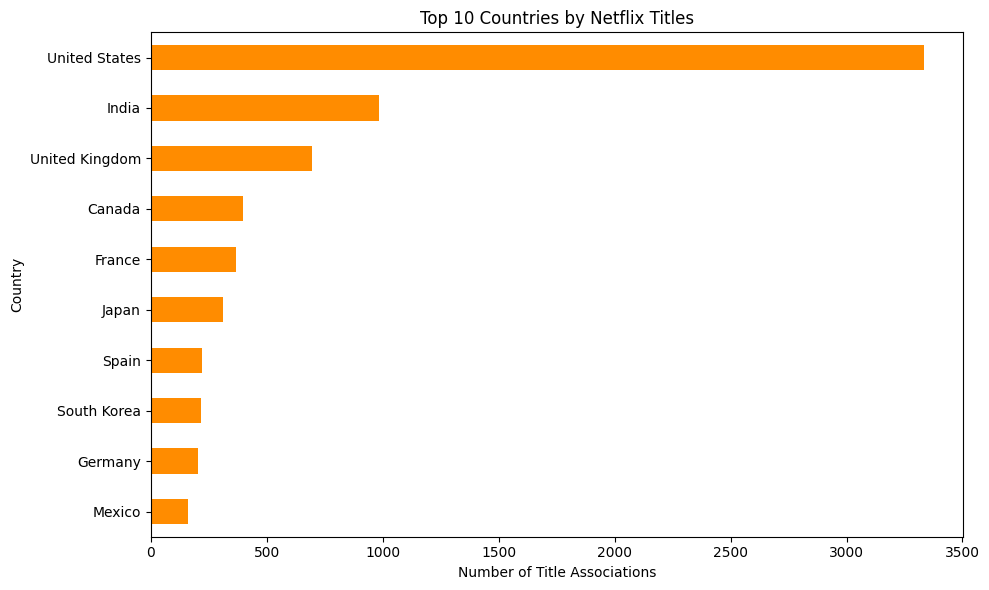


CONTENT RATING DISTRIBUTION
rating
TV-MA    3051
TV-14    2025
TV-PG     792
R         687
PG-13     407
TV-Y7     315
TV-Y      301
PG        249
TV-G      208
NR         66
Name: count, dtype: int64


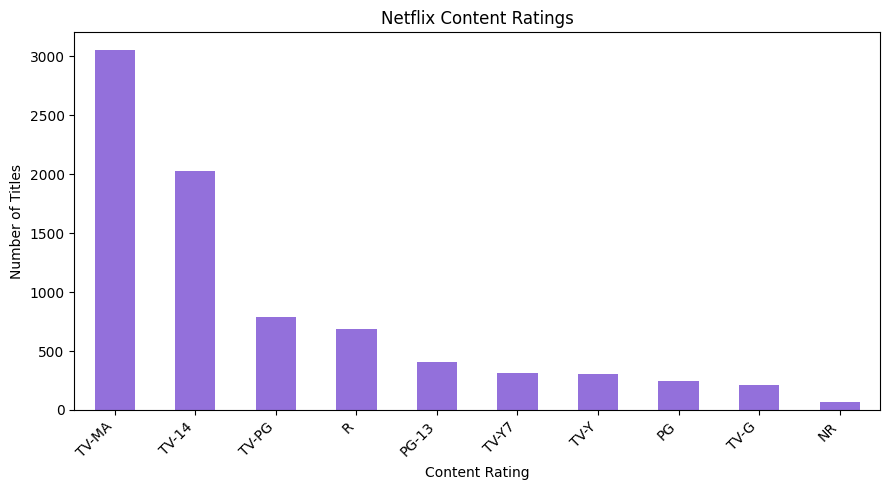


                 PROJECT SUMMARY
Total titles analyzed: 8154
Movies: 5597
TV shows: 2557
Most frequently listed genre: International Movies
Country with the most title associations: United States
Most common known content rating: TV-MA

PROJECT COMPLETED SUCCESSFULLY!
All analysis charts have been generated.

Cleaned dataset saved as: netflix_cleaned.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [4]:

# ============================================================
# NETFLIX CONTENT ANALYSIS
# A Beginner-Friendly Data Analytics Project
# Tools: Python, Pandas, Matplotlib
# ============================================================

# STEP 1: IMPORT LIBRARIES

import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

print("=" * 55)
print("       NETFLIX CONTENT ANALYSIS PROJECT")
print("=" * 55)


# STEP 2: LOAD THE DATASET

file_path = "netflix_titles.csv"

df = pd.read_csv(file_path)

print("\n1. DATASET LOADED SUCCESSFULLY!")
print("Original dataset shape:", df.shape)


# STEP 3: UNDERSTAND THE DATASET

print("\n2. FIRST FIVE ROWS")
display(df.head())

print("\n3. COLUMN NAMES")
print(df.columns.tolist())

print("\n4. DATASET INFORMATION")
df.info()

print("\n5. MISSING VALUES IN EACH COLUMN")
print(df.isnull().sum())

print("\n6. NUMBER OF EXACT DUPLICATE ROWS")
print(df.duplicated().sum())


# STEP 4: CLEAN THE DATA

original_rows = len(df)

# Remove exact duplicate rows
df = df.drop_duplicates().copy()

# Remove rows without a title
df = df.dropna(subset=["title"]).copy()

# Clean extra spaces in text columns
for col in df.select_dtypes(include=["object"]).columns:
    df[col] = df[col].apply(
        lambda x: x.strip() if isinstance(x, str) else x
    )

# Convert release year to numeric where possible
df["release_year"] = pd.to_numeric(
    df["release_year"], errors="coerce"
)

# Fill missing text values for selected columns
for col in ["director", "country", "rating", "duration",
            "listed_in", "cast", "date_added"]:
    if col in df.columns:
        df[col] = df[col].fillna("Unknown")

print("\n7. DATA CLEANING COMPLETED")
print("Rows before cleaning:", original_rows)
print("Rows after cleaning:", len(df))
print("Rows removed:", original_rows - len(df))


# STEP 5: GENERAL STATISTICS

total_titles = len(df)

movie_count = (df["type"] == "Movie").sum()
tv_count = (df["type"] == "TV Show").sum()

print("\n" + "=" * 55)
print("                 KEY STATISTICS")
print("=" * 55)

print("Total titles:", total_titles)
print("Total movies:", movie_count)
print("Total TV shows:", tv_count)

if total_titles > 0:
    print(f"Movies percentage: {movie_count / total_titles * 100:.2f}%")
    print(f"TV shows percentage: {tv_count / total_titles * 100:.2f}%")

print("\nContent type counts:")
print(df["type"].value_counts())


# STEP 6: MOVIES VS TV SHOWS CHART

type_counts = df["type"].value_counts()

plt.figure(figsize=(7, 5))
type_counts.plot(
    kind="bar",
    color=["tomato", "steelblue"]
)

plt.title("Netflix: Movies vs TV Shows")
plt.xlabel("Content Type")
plt.ylabel("Number of Titles")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


# STEP 7: TOP 10 GENRES

# Each title may have multiple genres.
# Split genres so each genre can be counted separately.

genre_data = (
    df["listed_in"]
    .dropna()
    .str.split(",")
    .explode()
    .str.strip()
)

genre_data = genre_data[genre_data != "Unknown"]
top_genres = genre_data.value_counts().head(10)

print("\nTOP 10 GENRES")
print(top_genres)

plt.figure(figsize=(10, 6))
top_genres.sort_values().plot(
    kind="barh",
    color="indianred"
)

plt.title("Top 10 Netflix Genres")
plt.xlabel("Number of Titles")
plt.ylabel("Genre")
plt.tight_layout()
plt.show()


# STEP 8: TITLES BY RELEASE YEAR

year_data = df["release_year"].dropna().astype(int)
year_counts = year_data.value_counts().sort_index()

print("\nRELEASE YEAR STATISTICS")
if not year_data.empty:
    print("Oldest release year:", year_data.min())
    print("Latest release year in dataset:", year_data.max())

# Focus on 2000 onwards for a readable chart
recent_year_counts = year_counts[year_counts.index >= 2000]

plt.figure(figsize=(12, 5))
plt.plot(
    recent_year_counts.index,
    recent_year_counts.values,
    marker="o",
    markersize=3
)

plt.title("Netflix Titles by Release Year (2000 Onwards)")
plt.xlabel("Release Year")
plt.ylabel("Number of Titles")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


# STEP 9: TOP 10 COUNTRIES

# A title may be associated with multiple countries.

country_data = (
    df["country"]
    .dropna()
    .str.split(",")
    .explode()
    .str.strip()
)

country_data = country_data[country_data != "Unknown"]
top_countries = country_data.value_counts().head(10)

print("\nTOP 10 COUNTRIES BY TITLE ASSOCIATIONS")
print(top_countries)

plt.figure(figsize=(10, 6))
top_countries.sort_values().plot(
    kind="barh",
    color="darkorange"
)

plt.title("Top 10 Countries by Netflix Titles")
plt.xlabel("Number of Title Associations")
plt.ylabel("Country")
plt.tight_layout()
plt.show()


# STEP 10: CONTENT RATINGS

rating_data = df["rating"].value_counts()
rating_data = rating_data.drop(
    labels=["Unknown"], errors="ignore"
).head(10)

print("\nCONTENT RATING DISTRIBUTION")
print(rating_data)

plt.figure(figsize=(9, 5))
rating_data.plot(
    kind="bar",
    color="mediumpurple"
)

plt.title("Netflix Content Ratings")
plt.xlabel("Content Rating")
plt.ylabel("Number of Titles")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()


# STEP 11: FINAL SUMMARY

print("\n" + "=" * 55)
print("                 PROJECT SUMMARY")
print("=" * 55)

print(f"Total titles analyzed: {len(df)}")
print(f"Movies: {movie_count}")
print(f"TV shows: {tv_count}")

if not top_genres.empty:
    print("Most frequently listed genre:", top_genres.index[0])

if not top_countries.empty:
    print("Country with the most title associations:",
          top_countries.index[0])

if not rating_data.empty:
    print("Most common known content rating:", rating_data.index[0])

print("\nPROJECT COMPLETED SUCCESSFULLY!")
print("All analysis charts have been generated.")


# STEP 12: SAVE THE CLEANED DATASET

output_file = "netflix_cleaned.csv"
df.to_csv(output_file, index=False)

print("\nCleaned dataset saved as:", output_file)

# Download the cleaned dataset to your computer in Colab
from google.colab import files
files.download(output_file)
